# 11 — Toronto multi-day thermal scenario selection

## Purpose

Notebook 10 expanded the observed mobility analysis to a summer station-day panel. The remaining limitation is that the thermal-accessibility layer is still based on one detailed SOLWEIG surface.

This notebook selects a compact, reproducible set of summer 2025 thermal scenarios for repeated SOLWEIG modelling. It preserves **25 July 2025** as the anchor event, identifies the hottest summer days, chooses matched same-weekday moderate reference days, uses a common **15:00** timestep, and saves a scenario manifest for the next batch-SOLWEIG notebook.

This notebook does not yet run SOLWEIG.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path("/scratch/project_2010417/paper3/heat-conditioned-accessibility")

TORONTO_RAW = PROJECT_ROOT / "data" / "toronto" / "raw"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"
PANEL_PATH = TORONTO_OUTPUTS / "bikeshare_panel" / "toronto_summer2025_station_day_panel.parquet"
SCENARIO_DIR = TORONTO_OUTPUTS / "thermal_scenarios"
SCENARIO_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Scenario output:", SCENARIO_DIR)

Project root: /scratch/project_2010417/paper3/heat-conditioned-accessibility
Scenario output: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/thermal_scenarios


## 2. Analysis design

In [2]:
START_DATE = pd.Timestamp("2025-06-01")
END_DATE = pd.Timestamp("2025-08-31")
ANCHOR_DATE = pd.Timestamp("2025-07-25")
ANALYSIS_HOUR = 15
N_HOT_DAYS = 6
HOT_QUANTILE = 0.90
MATCH_WINDOW_DAYS = 28

print("Anchor:", ANCHOR_DATE.date())
print("Common hour:", ANALYSIS_HOUR)

Anchor: 2025-07-25
Common hour: 15


## 3. Load U of T location

In [3]:
CENTER_PATH = TORONTO_RAW / "toronto_uoft_center.gpkg"

if not CENTER_PATH.exists():
    raise FileNotFoundError("U of T center file is missing.")

campus_center = gpd.read_file(CENTER_PATH).to_crs(4326)
LAT = float(campus_center.geometry.y.iloc[0])
LON = float(campus_center.geometry.x.iloc[0])

print("Latitude:", LAT)
print("Longitude:", LON)

Latitude: 43.66371033567467
Longitude: -79.39600762899782


## 4. Retrieve hourly summer weather

In [4]:
WEATHER_URL = "https://archive-api.open-meteo.com/v1/archive"

weather_params = {
    "latitude": LAT,
    "longitude": LON,
    "start_date": START_DATE.date().isoformat(),
    "end_date": END_DATE.date().isoformat(),
    "hourly": "temperature_2m,relative_humidity_2m,wind_speed_10m,shortwave_radiation",
    "timezone": "America/Toronto",
    "wind_speed_unit": "ms",
}

response = requests.get(WEATHER_URL, params=weather_params, timeout=120)
response.raise_for_status()
weather_json = response.json()

hourly = pd.DataFrame(weather_json["hourly"])
hourly["time"] = pd.to_datetime(hourly["time"])
hourly["date"] = hourly["time"].dt.normalize()
hourly["hour"] = hourly["time"].dt.hour

print("Hourly weather rows:", len(hourly))

Hourly weather rows: 2208


## 5. Construct daily weather table

In [5]:
daily_tmax = hourly.groupby("date")["temperature_2m"].max().rename("tmax_c")

at_1500 = (
    hourly[hourly["hour"] == ANALYSIS_HOUR]
    .set_index("date")[["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "shortwave_radiation"]]
    .rename(columns={
        "temperature_2m": "temp_1500_c",
        "relative_humidity_2m": "rh_1500_pct",
        "wind_speed_10m": "wind_1500_ms",
        "shortwave_radiation": "sw_1500_wm2",
    })
)

daily = pd.concat([daily_tmax, at_1500], axis=1).reset_index()
daily["weekday"] = daily["date"].dt.day_name()
display(daily.head())

,date,tmax_c,temp_1500_c,rh_1500_pct,wind_1500_ms,sw_1500_wm2,weekday
0,2025-06-01,15.8,15.5,47,6.30,648.0,Sunday
1,2025-06-02,21.7,21.4,33,3.44,913.0,Monday
2,2025-06-03,23.7,23.1,51,5.41,902.0,Tuesday
3,2025-06-04,28.4,26.8,52,6.18,799.0,Wednesday
4,2025-06-05,21.8,21.8,64,2.10,721.0,Thursday


## 6. Define hottest summer days

In [6]:
hot_threshold = float(daily["tmax_c"].quantile(HOT_QUANTILE))
daily["top_decile_hot"] = daily["tmax_c"] >= hot_threshold

hottest = daily.sort_values("tmax_c", ascending=False).head(N_HOT_DAYS).copy()

print("Top-decile threshold:", round(hot_threshold, 2), "°C")
display(hottest[["date", "weekday", "tmax_c", "temp_1500_c", "rh_1500_pct", "wind_1500_ms", "sw_1500_wm2"]])

Top-decile threshold: 31.26 °C


,date,weekday,tmax_c,temp_1500_c,rh_1500_pct,wind_1500_ms,sw_1500_wm2
23,2025-06-24,Tuesday,35.9,35.9,32,5.71,761.0
22,2025-06-23,Monday,35.6,35.1,40,4.60,833.0
21,2025-06-22,Sunday,32.8,31.5,66,2.28,777.0
56,2025-07-27,Sunday,32.8,32.2,44,3.69,798.0
53,2025-07-24,Thursday,32.4,31.6,55,5.62,747.0
35,2025-07-06,Sunday,32.2,32.2,40,6.36,784.0


## 7. Preserve the 25 July anchor event

In [7]:
if ANCHOR_DATE not in set(hottest["date"]):
    anchor_row = daily[daily["date"] == ANCHOR_DATE].copy()
    if anchor_row.empty:
        raise RuntimeError("Anchor date is absent from weather data.")
    hottest = pd.concat([hottest, anchor_row], ignore_index=True)

hottest = (
    hottest.drop_duplicates(subset="date")
    .sort_values("date")
    .reset_index(drop=True)
)
hottest["is_anchor"] = hottest["date"] == ANCHOR_DATE

print("Hot scenarios including anchor:", len(hottest))
display(hottest[["date", "weekday", "tmax_c", "is_anchor"]])

Hot scenarios including anchor: 7


,date,weekday,tmax_c,is_anchor
0,2025-06-22,Sunday,32.8,False
1,2025-06-23,Monday,35.6,False
2,2025-06-24,Tuesday,35.9,False
3,2025-07-06,Sunday,32.2,False
4,2025-07-24,Thursday,32.4,False
5,2025-07-25,Friday,29.7,True
6,2025-07-27,Sunday,32.8,False


## 8. Select matched same-weekday moderate reference days

In [8]:
summer_median_tmax = float(daily["tmax_c"].median())
used_reference_dates = set()
reference_rows = []

for _, hot in hottest.iterrows():
    candidates = daily[(daily["weekday"] == hot["weekday"]) & (~daily["top_decile_hot"]) & (daily["date"] != hot["date"])].copy()
    candidates["day_distance"] = (candidates["date"] - hot["date"]).abs().dt.days

    near = candidates[candidates["day_distance"] <= MATCH_WINDOW_DAYS].copy()
    if not near.empty:
        candidates = near

    candidates = candidates[~candidates["date"].isin(used_reference_dates)].copy()
    if candidates.empty:
        raise RuntimeError(f"No reference candidate available for {hot['date'].date()}.")

    candidates["median_temp_distance"] = (candidates["tmax_c"] - summer_median_tmax).abs()
    temp_scale = max(daily["tmax_c"].std(), 1.0)
    candidates["match_score"] = candidates["median_temp_distance"] / temp_scale + 0.25 * (candidates["day_distance"] / MATCH_WINDOW_DAYS)

    best = candidates.sort_values(["match_score", "day_distance"]).iloc[0].copy()
    used_reference_dates.add(best["date"])
    best["matched_hot_date"] = hot["date"]
    reference_rows.append(best)

references = pd.DataFrame(reference_rows)
display(references[["matched_hot_date", "date", "weekday", "tmax_c", "temp_1500_c", "day_distance", "match_score"]])

,matched_hot_date,date,weekday,tmax_c,temp_1500_c,day_distance,match_score
28,2025-06-22,2025-06-29,Sunday,25.4,25.0,7,0.171026
15,2025-06-23,2025-06-16,Monday,24.7,24.3,7,0.339844
37,2025-06-24,2025-07-08,Tuesday,25.3,24.8,14,0.257643
49,2025-07-06,2025-07-20,Sunday,26.3,26.3,14,0.233526
32,2025-07-24,2025-07-03,Thursday,25.7,24.4,21,0.223675
75,2025-07-25,2025-08-15,Friday,26.7,26.4,21,0.392493
77,2025-07-27,2025-08-17,Sunday,25.6,25.0,21,0.247792


## 9. Build the scenario manifest

In [9]:
hot_manifest = hottest[["date", "weekday", "tmax_c", "temp_1500_c", "rh_1500_pct", "wind_1500_ms", "sw_1500_wm2", "is_anchor"]].copy()
hot_manifest["scenario_role"] = "hot"
hot_manifest["pair_hot_date"] = hot_manifest["date"]

ref_manifest = references[["date", "weekday", "tmax_c", "temp_1500_c", "rh_1500_pct", "wind_1500_ms", "sw_1500_wm2", "matched_hot_date"]].copy()
ref_manifest["scenario_role"] = "reference"
ref_manifest["pair_hot_date"] = ref_manifest["matched_hot_date"]
ref_manifest["is_anchor"] = False
ref_manifest = ref_manifest.drop(columns="matched_hot_date")

scenario_manifest = pd.concat([hot_manifest, ref_manifest], ignore_index=True)
scenario_manifest["analysis_hour"] = ANALYSIS_HOUR
scenario_manifest["scenario_id"] = scenario_manifest["scenario_role"] + "_" + scenario_manifest["date"].dt.strftime("%Y-%m-%d") + "_1500"
scenario_manifest = scenario_manifest.sort_values(["pair_hot_date", "scenario_role"]).reset_index(drop=True)
display(scenario_manifest)

,date,weekday,tmax_c,temp_1500_c,rh_1500_pct,wind_1500_ms,sw_1500_wm2,is_anchor,scenario_role,pair_hot_date,analysis_hour,scenario_id
0,2025-06-22,Sunday,32.8,31.5,66,2.28,777.0,False,hot,2025-06-22,15,hot_2025-06-22_1500
1,2025-06-29,Sunday,25.4,25.0,45,3.18,891.0,False,reference,2025-06-22,15,reference_2025-06-29_1500
2,2025-06-23,Monday,35.6,35.1,40,4.60,833.0,False,hot,2025-06-23,15,hot_2025-06-23_1500
3,2025-06-16,Monday,24.7,24.3,53,1.76,806.0,False,reference,2025-06-23,15,reference_2025-06-16_1500
4,2025-06-24,Tuesday,35.9,35.9,32,5.71,761.0,False,hot,2025-06-24,15,hot_2025-06-24_1500
5,2025-07-08,Tuesday,25.3,24.8,62,3.00,547.0,False,reference,2025-06-24,15,reference_2025-07-08_1500
6,2025-07-06,Sunday,32.2,32.2,40,6.36,784.0,False,hot,2025-07-06,15,hot_2025-07-06_1500
7,2025-07-20,Sunday,26.3,26.3,52,4.57,836.0,False,reference,2025-07-06,15,reference_2025-07-20_1500
8,2025-07-24,Thursday,32.4,31.6,55,5.62,747.0,False,hot,2025-07-24,15,hot_2025-07-24_1500
9,2025-07-03,Thursday,25.7,24.4,38,5.73,907.0,False,reference,2025-07-24,15,reference_2025-07-03_1500


## 10. Pairwise temperature contrasts

In [10]:
hot_pair = (scenario_manifest[scenario_manifest["scenario_role"] == "hot"][["pair_hot_date", "tmax_c", "temp_1500_c"]].rename(columns={"tmax_c": "hot_tmax_c", "temp_1500_c": "hot_temp_1500_c"}))
ref_pair = (scenario_manifest[scenario_manifest["scenario_role"] == "reference"][["pair_hot_date", "tmax_c", "temp_1500_c"]].rename(columns={"tmax_c": "reference_tmax_c", "temp_1500_c": "reference_temp_1500_c"}))

pair_summary = hot_pair.merge(ref_pair, on="pair_hot_date", how="left")
pair_summary["delta_tmax_c"] = pair_summary["hot_tmax_c"] - pair_summary["reference_tmax_c"]
pair_summary["delta_temp_1500_c"] = pair_summary["hot_temp_1500_c"] - pair_summary["reference_temp_1500_c"]
display(pair_summary)

,pair_hot_date,hot_tmax_c,hot_temp_1500_c,reference_tmax_c,reference_temp_1500_c,delta_tmax_c,delta_temp_1500_c
0,2025-06-22,32.8,31.5,25.4,25.0,7.4,6.5
1,2025-06-23,35.6,35.1,24.7,24.3,10.9,10.8
2,2025-06-24,35.9,35.9,25.3,24.8,10.6,11.1
3,2025-07-06,32.2,32.2,26.3,26.3,5.9,5.9
4,2025-07-24,32.4,31.6,25.7,24.4,6.7,7.2
5,2025-07-25,29.7,29.0,26.7,26.4,3.0,2.6
6,2025-07-27,32.8,32.2,25.6,25.0,7.2,7.2


## 11. Visualize selected scenarios

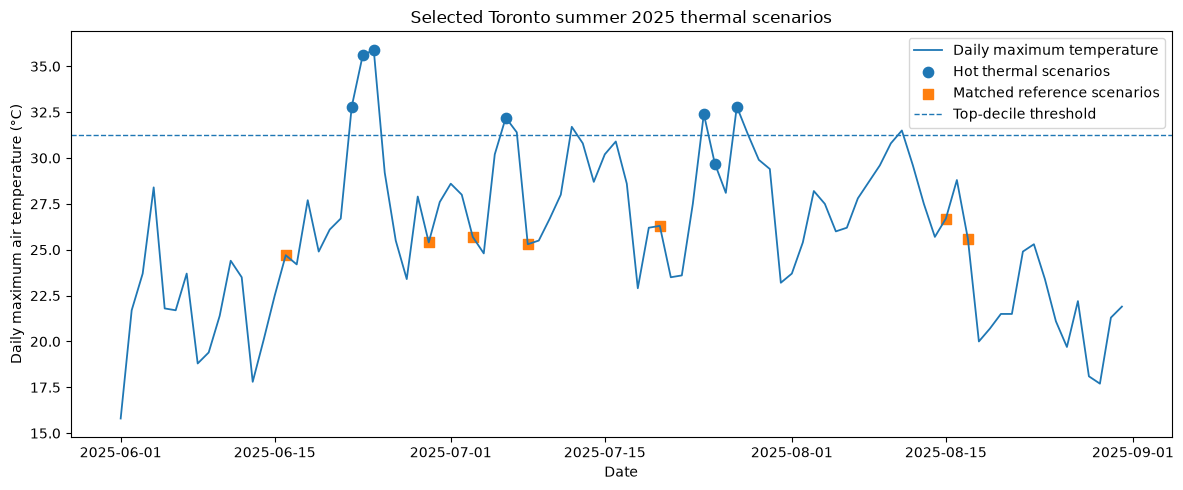

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily["date"], daily["tmax_c"], linewidth=1.3, label="Daily maximum temperature")

hot_points = scenario_manifest[scenario_manifest["scenario_role"] == "hot"]
ref_points = scenario_manifest[scenario_manifest["scenario_role"] == "reference"]

ax.scatter(hot_points["date"], hot_points["tmax_c"], s=55, label="Hot thermal scenarios")
ax.scatter(ref_points["date"], ref_points["tmax_c"], s=55, marker="s", label="Matched reference scenarios")
ax.axhline(hot_threshold, linestyle="--", linewidth=1, label="Top-decile threshold")
ax.set_xlabel("Date")
ax.set_ylabel("Daily maximum air temperature (°C)")
ax.set_title("Selected Toronto summer 2025 thermal scenarios")
ax.legend()
plt.tight_layout()
plt.show()

## 12. Inspect 15:00 meteorological contrast

In [12]:
display(
    scenario_manifest[[
        "scenario_id", "scenario_role", "date", "temp_1500_c",
        "rh_1500_pct", "wind_1500_ms", "sw_1500_wm2", "is_anchor"
    ]].sort_values("temp_1500_c", ascending=False)
)

,scenario_id,scenario_role,date,temp_1500_c,rh_1500_pct,wind_1500_ms,sw_1500_wm2,is_anchor
4,hot_2025-06-24_1500,hot,2025-06-24,35.9,32,5.71,761.0,False
2,hot_2025-06-23_1500,hot,2025-06-23,35.1,40,4.60,833.0,False
12,hot_2025-07-27_1500,hot,2025-07-27,32.2,44,3.69,798.0,False
6,hot_2025-07-06_1500,hot,2025-07-06,32.2,40,6.36,784.0,False
8,hot_2025-07-24_1500,hot,2025-07-24,31.6,55,5.62,747.0,False
0,hot_2025-06-22_1500,hot,2025-06-22,31.5,66,2.28,777.0,False
10,hot_2025-07-25_1500,hot,2025-07-25,29.0,51,0.78,556.0,True
11,reference_2025-08-15_1500,reference,2025-08-15,26.4,59,2.66,838.0,False
7,reference_2025-07-20_1500,reference,2025-07-20,26.3,52,4.57,836.0,False
1,reference_2025-06-29_1500,reference,2025-06-29,25.0,45,3.18,891.0,False


## 13. Optional linkage to Notebook 10 mobility panel

In [13]:
if PANEL_PATH.exists():
    panel = pd.read_parquet(PANEL_PATH)
    panel["date"] = pd.to_datetime(panel["date"])

    mobility_daily = (
        panel.groupby("date")
        .agg(
            city_trips=("city_trips", "first"),
            mean_station_trips=("station_trips", "mean"),
            mean_weekday_adjusted_response=("weekday_adjusted_response", "mean"),
        )
        .reset_index()
    )

    scenario_mobility = scenario_manifest.merge(mobility_daily, on="date", how="left")
    display(scenario_mobility[["scenario_id", "scenario_role", "tmax_c", "temp_1500_c", "city_trips", "mean_station_trips", "mean_weekday_adjusted_response"]])
else:
    scenario_mobility = None
    print("Notebook 10 panel not found; mobility diagnostic skipped.")

,scenario_id,scenario_role,tmax_c,temp_1500_c,city_trips,mean_station_trips,mean_weekday_adjusted_response
0,hot_2025-06-22_1500,hot,32.8,31.5,31893,52.800000,-0.157743
1,reference_2025-06-29_1500,reference,25.4,25.0,37307,61.600000,-0.104702
2,hot_2025-06-23_1500,hot,35.6,35.1,30693,62.333333,-0.125108
3,reference_2025-06-16_1500,reference,24.7,24.3,32484,67.453333,-0.052186
4,hot_2025-06-24_1500,hot,35.9,35.9,34169,63.986667,-0.148795
5,reference_2025-07-08_1500,reference,25.3,24.8,39453,74.413333,0.008626
6,hot_2025-07-06_1500,hot,32.2,32.2,36282,54.880000,-0.155131
7,reference_2025-07-20_1500,reference,26.3,26.3,38523,61.213333,0.034911
8,hot_2025-07-24_1500,hot,32.4,31.6,36131,67.600000,-0.108421
9,reference_2025-07-03_1500,reference,25.7,24.4,38701,73.733333,-0.044016


## 14. Save scenario outputs

In [14]:
MANIFEST_PATH = SCENARIO_DIR / "toronto_summer2025_solweig_scenario_manifest.csv"
PAIRS_PATH = SCENARIO_DIR / "toronto_summer2025_hot_reference_pairs.csv"

scenario_manifest.to_csv(MANIFEST_PATH, index=False)
pair_summary.to_csv(PAIRS_PATH, index=False)

if scenario_mobility is not None:
    scenario_mobility.to_csv(SCENARIO_DIR / "toronto_summer2025_scenario_mobility_diagnostic.csv", index=False)

print("Saved:")
print("-", MANIFEST_PATH)
print("-", PAIRS_PATH)

Saved:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/thermal_scenarios/toronto_summer2025_solweig_scenario_manifest.csv
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/thermal_scenarios/toronto_summer2025_hot_reference_pairs.csv


## 15. Final diagnostics

In [15]:
print("Hot scenarios:", int((scenario_manifest["scenario_role"] == "hot").sum()))
print("Reference scenarios:", int((scenario_manifest["scenario_role"] == "reference").sum()))
print("Total SOLWEIG scenarios:", len(scenario_manifest))
print("Top-decile threshold:", round(hot_threshold, 2), "°C")
print("Mean hot-reference ΔTmax:", round(pair_summary["delta_tmax_c"].mean(), 2), "°C")
print("Mean hot-reference ΔT at 15:00:", round(pair_summary["delta_temp_1500_c"].mean(), 2), "°C")
print("Anchor retained:", bool((scenario_manifest["date"] == ANCHOR_DATE).any()))

Hot scenarios: 7
Reference scenarios: 7
Total SOLWEIG scenarios: 14
Top-decile threshold: 31.26 °C
Mean hot-reference ΔTmax: 7.39 °C
Mean hot-reference ΔT at 15:00: 7.33 °C
Anchor retained: True


## What Notebook 12 should do

Notebook 12 should take the saved scenario manifest and run the **same U of T SOLWEIG configuration** for each selected 15:00 scenario while keeping urban form fixed.

For every scenario it should save Tmrt, UTCI, metadata, and raster summary statistics. After that, thermal-network impedance and accessibility can be recomputed for every scenario.

This produces the stronger chain:

**weather scenario → spatial UTCI → thermal network impedance → accessibility loss → observed Bike Share response**